---
title: "LinUCB for ad selection"
author: "Fabian"
date: "2026-01-10"
categories: [RL]
format:
  html:
    code-fold: false
    toc: true
jupyter: python3
draft: False
---

This guide details the **Contextual Upper Confidence Bound (LinUCB)** algorithm.

In standard A/B testing or Multi-Armed Bandits (MAB), we treat all users the same. In **Contextual Bandits**, we assume the "best" ad depends on the user's *context* (e.g., a 20-year-old on a mobile phone might prefer a Gaming Ad, while a 50-year-old on a Desktop might prefer an Investment Ad).

The algorithm balances **Exploitation** (showing the ad we think is best for *this* person) and **Exploration** (trying an ad we are uncertain about to learn more).

---

### 1. The Mathematical Model (LinUCB)

We use the **Disjoint LinUCB** algorithm. "Disjoint" means we learn a separate prediction model for each Ad (Arm).

For a specific Ad  and a user with context vector  (containing demographics/device data):

1. **Prediction:** We predict the expected reward (Click-Through Rate) using a linear relationship:



where  is the weight vector learned for Ad .
2. **Confidence Interval (Uncertainty):** We calculate how "unsure" we are about this prediction.


*  is a matrix storing the covariance of contexts seen so far for Ad .
*  is a hyperparameter controlling how much we want to explore.


3. **Decision Rule:** Select the Ad that maximizes the Upper Confidence Bound:



---

### 2. Python Implementation & Visualization

This script simulates users with specific preferences, runs the LinUCB algorithm, and visualizes how it learns to target ads correctly over time.


In [1]:

import numpy as np
import matplotlib.pyplot as plt

# --- 1. Environment Simulation ---
class UserEnvironment:
    def __init__(self):
        # Ads (Arms)
        self.ads = ["Tech_Gadget", "Retirement_Plan", "Fashion_Sale"]
        self.n_arms = len(self.ads)
        
        # Feature Mapping: [Bias, Age_Normalized, Is_Mobile]
        # Context dimension d = 3
        self.d = 3 

    def get_user_context(self):
        """Simulate a random user visiting the site."""
        age = np.random.uniform(18, 70)
        is_mobile = np.random.choice([0, 1])
        
        # Normalize age to 0-1 range for stability
        age_norm = (age - 18) / (70 - 18)
        
        # Context vector: [Bias Term, Age, Device]
        context = np.array([1.0, age_norm, is_mobile])
        return context, age, is_mobile

    def get_reward(self, arm_index, context):
        """
        Simulate user clicking (Reward=1) or not (Reward=0) based on hidden preferences.
        Preferences (Unknown to algorithm):
        - Ad 0 (Tech): Likes Young people + Mobile users
        - Ad 1 (Retirement): Likes Older people + Desktop users
        - Ad 2 (Fashion): Random/General appeal
        """
        age_feature = context[1]  # 0.0 (young) to 1.0 (old)
        mobile_feature = context[2]
        
        # Calculate 'True' Probability of Click (CTR)
        if arm_index == 0: # Tech Gadget
            prob = 0.8 * (1 - age_feature) + 0.2 * mobile_feature 
        elif arm_index == 1: # Retirement Plan
            prob = 0.8 * age_feature + 0.2 * (1 - mobile_feature)
        else: # Fashion
            prob = 0.15 # Low constant appeal
            
        prob = np.clip(prob, 0, 0.95) # Cap prob
        return 1 if np.random.rand() < prob else 0


In [2]:

# --- 2. LinUCB Algorithm ---
class LinUCB:
    def __init__(self, n_arms, n_features, alpha=2.5):
        self.n_arms = n_arms
        self.n_features = n_features
        self.alpha = alpha
        
        # Initialize A (Covariance) and b (Reward vector) for each arm
        # A is initialized as Identity matrix
        self.A = [np.identity(n_features) for _ in range(n_arms)]
        # b is initialized as zero vector
        self.b = [np.zeros(n_features) for _ in range(n_arms)]

    def select_arm(self, context):
        ucb_values = []
        
        for a in range(self.n_arms):
            # 1. Estimate Theta (Weight vector) -> theta = inv(A) * b
            A_inv = np.linalg.inv(self.A[a])
            theta = np.dot(A_inv, self.b[a])
            
            # 2. Predict Reward (Exploitation)
            pred_reward = np.dot(theta, context)
            
            # 3. Calculate Uncertainty (Exploration Bonus)
            # standard_deviation = sqrt(x.T * inv(A) * x)
            uncertainty = np.sqrt(np.dot(context.T, np.dot(A_inv, context)))
            
            # 4. Upper Confidence Bound
            ucb = pred_reward + self.alpha * uncertainty
            ucb_values.append(ucb)
            
        return np.argmax(ucb_values)

    def update(self, arm, context, reward):
        # Update A and b for the selected arm only
        # A += x * x.T
        self.A[arm] += np.outer(context, context)
        # b += reward * x
        self.b[arm] += reward * context


In [4]:

# --- 3. Simulation Loop ---
env = UserEnvironment()
agent = LinUCB(n_arms=env.n_arms, n_features=env.d, alpha=2.0)

n_rounds = 2000
ctr_history = []
clicks = 0
aligned_ad_choices = [] # To track if we showed 'correct' ad

for t in range(1, n_rounds + 1):
    # 1. A user arrives
    context, age_raw, is_mobile = env.get_user_context()
    
    # 2. Agent picks an Ad
    chosen_arm = agent.select_arm(context)
    
    # 3. User reacts (Click or No Click)
    reward = env.get_reward(chosen_arm, context)
    
    # 4. Agent learns
    agent.update(chosen_arm, context, reward)
    
    # Metrics
    clicks += reward
    ctr_history.append(clicks / t)
    
    # Heuristic check for visualization: Did we pick the "logic" best ad?
    # Young (<45) -> Tech(0), Old (>45) -> Retirement(1)
    if age_raw < 45 and chosen_arm == 0: aligned_ad_choices.append(1)
    elif age_raw >= 45 and chosen_arm == 1: aligned_ad_choices.append(1)
    else: aligned_ad_choices.append(0)



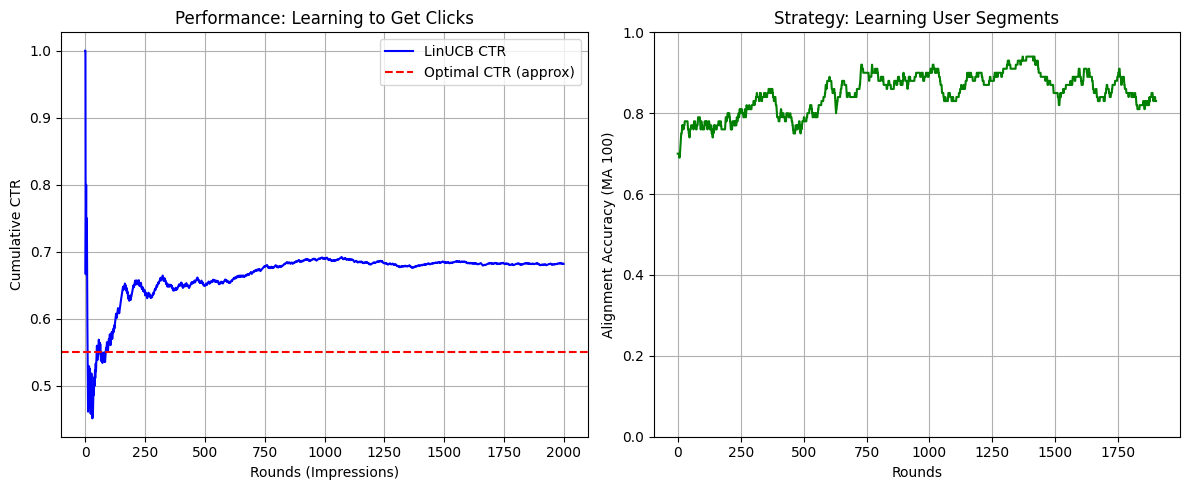

In [5]:

# --- 4. Visualizations ---
plt.figure(figsize=(12, 5))

# Plot 1: Click-Through Rate (CTR) Evolution
plt.subplot(1, 2, 1)
plt.plot(ctr_history, label="LinUCB CTR", color='blue')
plt.axhline(y=0.55, color='r', linestyle='--', label="Optimal CTR (approx)")
plt.xlabel("Rounds (Impressions)")
plt.ylabel("Cumulative CTR")
plt.title("Performance: Learning to Get Clicks")
plt.legend()
plt.grid(True)

# Plot 2: Decision Accuracy Moving Average
def moving_average(x, w):
    return np.convolve(x, np.ones(w), 'valid') / w

plt.subplot(1, 2, 2)
ma_window = 100
acc_ma = moving_average(aligned_ad_choices, ma_window)
plt.plot(acc_ma, color='green')
plt.xlabel("Rounds")
plt.ylabel(f"Alignment Accuracy (MA {ma_window})")
plt.title("Strategy: Learning User Segments")
plt.grid(True)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


### 3. Deep Dive: What is happening in the code?

#### A. The Context Vector ()

In the `get_user_context` function, we turn a user into numbers.

* **User:** 25 years old, using an iPhone.
* **Vector:** `[1.0, 0.14, 1.0]`
* `1.0`: The bias term (essential for linear regression to find a baseline intercept).
* `0.14`: Normalized age (Young is close to 0, Old close to 1).
* `1.0`: Mobile device (Binary flag).



#### B. The Matrix  (The "Memory")

Each ad (arm) has its own matrix .

* Initially,  is an Identity matrix. The algorithm knows nothing; the "uncertainty" term () is large for everyone.
* **As we show Ad 0 to young people**, the matrix  changes shape. It "rotates" to align with the vector of young people.
* The math  effectively asks: *"Have I seen a vector like  before for this ad?"*
* **Yes:** The value is small  Low Uncertainty  Rely on prediction (Exploit).
* **No:** The value is large  High Uncertainty  Add huge bonus  Pick this ad to learn (Explore).



#### C. The Alpha () Parameter

In `LinUCB(..., alpha=2.0)`, this controls your risk appetite.

* **High Alpha:** The algorithm acts curious. It will show "Retirement Plans" to a 20-year-old just to be *absolutely sure* they don't click on it.
* **Low Alpha:** The algorithm acts greedy. As soon as it sees one click from a young person on a "Tech" ad, it stops testing other ads and spams "Tech" to all young people.

### 4. Interpreting the Visualizations

If you run the code above, you will see two charts:

1. **Performance (Left Chart):**
* The curve starts volatile (random guessing).
* It quickly stabilizes and trends upward.
* It should approach the "Optimal CTR" (red line). This proves the algorithm learned that showing random ads yields low clicks (~15%), but targeting yields high clicks (~50-60%).


2. **Strategy (Right Chart):**
* This plots "Alignment Accuracy." It asks: *Did the algorithm show the Tech Ad to a young person or the Retirement Ad to an older person?*
* Initially, this will hover around 0.33 (random chance among 3 ads).
* Over time, it will rise toward 0.9 or 1.0, showing that the algorithm has successfully "segmented" the users without us explicitly programming `if age < 30`.

